In [1]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
# 2. Load dataset
df = pd.read_csv("City_Air_Quality (1).csv", encoding='latin1')


<ipython-input-5-cd182eccb6a1>:2: DtypeWarning: Columns (0: stn_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("City_Air_Quality (1).csv", encoding='latin1')


In [6]:
# 3. Explore data
print(df.head())
df.info()
print(df.isnull().sum())

  stn_code       sampling_date           state   location agency  \
0    150.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
1    151.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
2    152.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
3    150.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   
4    151.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   

                                 type  so2   no2  rspm  spm  \
0  Residential, Rural and other Areas  4.8  17.4   NaN  NaN   
1                     Industrial Area  3.1   7.0   NaN  NaN   
2  Residential, Rural and other Areas  6.2  28.5   NaN  NaN   
3  Residential, Rural and other Areas  6.3  14.7   NaN  NaN   
4                     Industrial Area  4.7   7.5   NaN  NaN   

  location_monitoring_station  pm2_5        date  
0                         NaN    NaN  1990-02-01  
1                         NaN    NaN  1990-02-01  
2                         NaN    NaN  1990-02-01  
3       

In [7]:
# 4. Select important columns
df = df[['date', 'location', 'so2', 'no2', 'rspm', 'spm', 'pm2_5']]

In [8]:
# 5. Handle missing values
cols = ['so2', 'no2', 'rspm', 'spm', 'pm2_5']
df[cols] = df[cols].fillna(df[cols].median())

In [9]:
# 6. Convert date into datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.dropna(subset=['date'])


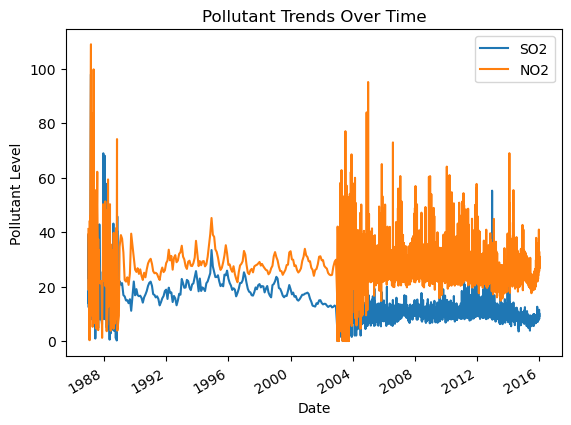

In [10]:
# 7. Line plot – pollutant trends
df.groupby('date')['so2'].mean().plot(label='SO2')
df.groupby('date')['no2'].mean().plot(label='NO2')
plt.title("Pollutant Trends Over Time")
plt.xlabel("Date")
plt.ylabel("Pollutant Level")
plt.legend()
plt.show()

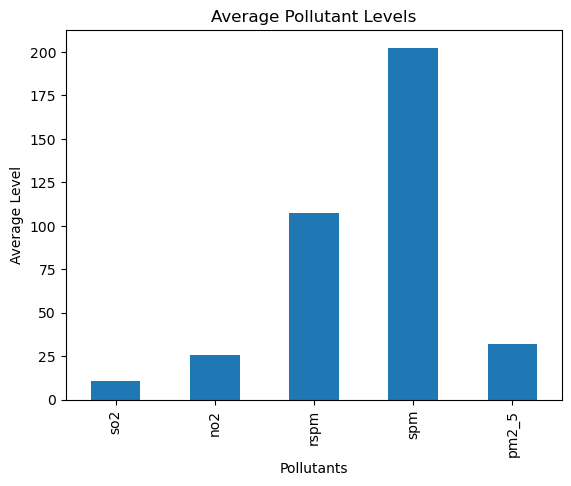

In [11]:
# 8. Bar plot – average pollutant levels
df[cols].mean().plot(kind='bar')
plt.title("Average Pollutant Levels")
plt.xlabel("Pollutants")
plt.ylabel("Average Level")
plt.show()

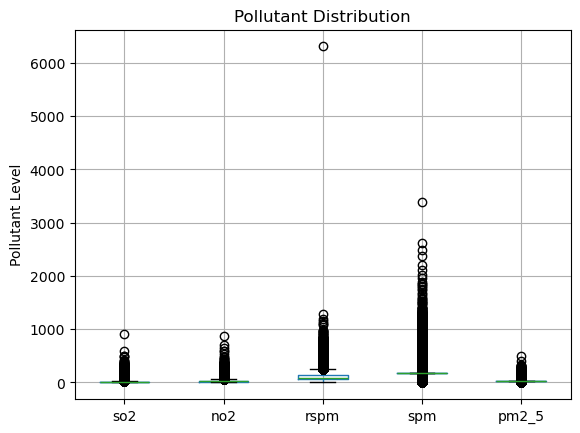

In [12]:
# 9. Boxplot – pollutant distribution
df[cols].boxplot()
plt.title("Pollutant Distribution")
plt.ylabel("Pollutant Level")
plt.show()


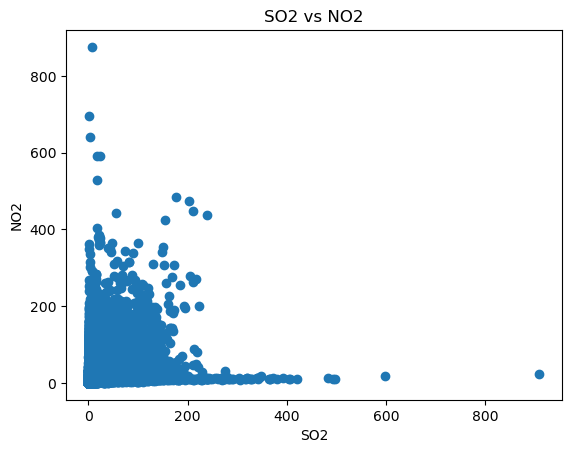

In [13]:
# 10. Scatter plot – relationship between pollutants
plt.scatter(df['so2'], df['no2'])
plt.title("SO2 vs NO2")
plt.xlabel("SO2")
plt.ylabel("NO2")
plt.show()

In [14]:
# 11. Display final data
print(df.head())
print("Dataset Shape:", df.shape)

        date   location  so2   no2  rspm    spm  pm2_5
0 1990-02-01  Hyderabad  4.8  17.4  90.0  187.0   32.0
1 1990-02-01  Hyderabad  3.1   7.0  90.0  187.0   32.0
2 1990-02-01  Hyderabad  6.2  28.5  90.0  187.0   32.0
3 1990-03-01  Hyderabad  6.3  14.7  90.0  187.0   32.0
4 1990-03-01  Hyderabad  4.7   7.5  90.0  187.0   32.0
Dataset Shape: (435735, 7)
